# Extracting Structured Data from PDFs

In this demo, we extract a validated schema from two TV station invoices for political ads, one digital and one scanned, then compare each field with the annotated ground truth.

The invoices come from the [VRDU benchmark](https://github.com/google-research-datasets/vrdu). Download them first with `python3 ../data/setup_data.py`.

In [9]:
import sys
from pathlib import Path

from dotenv import load_dotenv

load_dotenv(".env")  # reads OPENAI_API_KEY and OPENAI_BASE_URL from .env in this folder

sys.path.insert(0, str(Path("..").resolve()))

DIGITAL = Path("../data/pdfs/f4134faa-3183-9843-02f8-30794296ddcc.pdf")
SCANNED = Path("../data/pdfs/414817-collect-files-53928-political-file-2012-non.pdf")

## 1. Digital Invoice

pdfplumber reads the text, and the position of every word on the page.

In [10]:
import pdfplumber

with pdfplumber.open(DIGITAL) as pdf:
    page = pdf.pages[0]
    print(
        f"Digital invoice, page 1 of {len(pdf.pages)}: {len(page.chars)} characters\n"
    )
    print("\n".join(page.extract_text().splitlines()[:20]))
    print(
        "\nThe first words, with their position on the page (in points from the top left):\n"
    )
    for word in page.extract_words()[:12]:
        print(f"  {word['text']:<20} x={word['x0']:6.1f}  y={word['top']:6.1f}")

Digital invoice, page 1 of 1: 2567 characters

Contract Agreement Between: Print Date 10/07/19 Page 1 of 1
CONTRACT
WYCW Contract / Revision Alt Order #
2960 North Meridian Street 2186808 / 26660858
Jill Hammons Advertiser Original Date / Revision
Indianapolis, IN 46208 POL/Joe Biden/President/US/Dem 10/07/19 / 10/07/19
(864) 587-7777 Contract Dates Estimate #
01/28/20 - 02/03/20 6834
Product
Primary
And: Billing Cycle Billing Calendar Cash/Trade
EOM Broadcast Cash
Media Buying and Analytics
2020 Howell Mill Rd Property Account Executive Sales Office
NW Suite D-348 WYCW Katz Washington Katz/Washington
Atlanta, GA 30318 Special Handling
Demographic
Men 35+
Agy Code Advertiser Code Product 1/2
1106 1271

The first words, with their position on the page (in points from the top left):

  Contract             x=  18.0  y=  18.9
  Agreement            x=  50.6  y=  18.9
  Between:             x=  92.3  y=  18.9
  Print                x= 430.0  y=  18.9
  Date                 x= 448.8  y=  18

## 2. A scanned PDF is an image of a page

pdfplumber finds no text in it, so we turn the page into an image for a multimodal model.

Scanned invoice, page 1 of 1: 0 characters, 1 image
Text pdfplumber extracts: ''


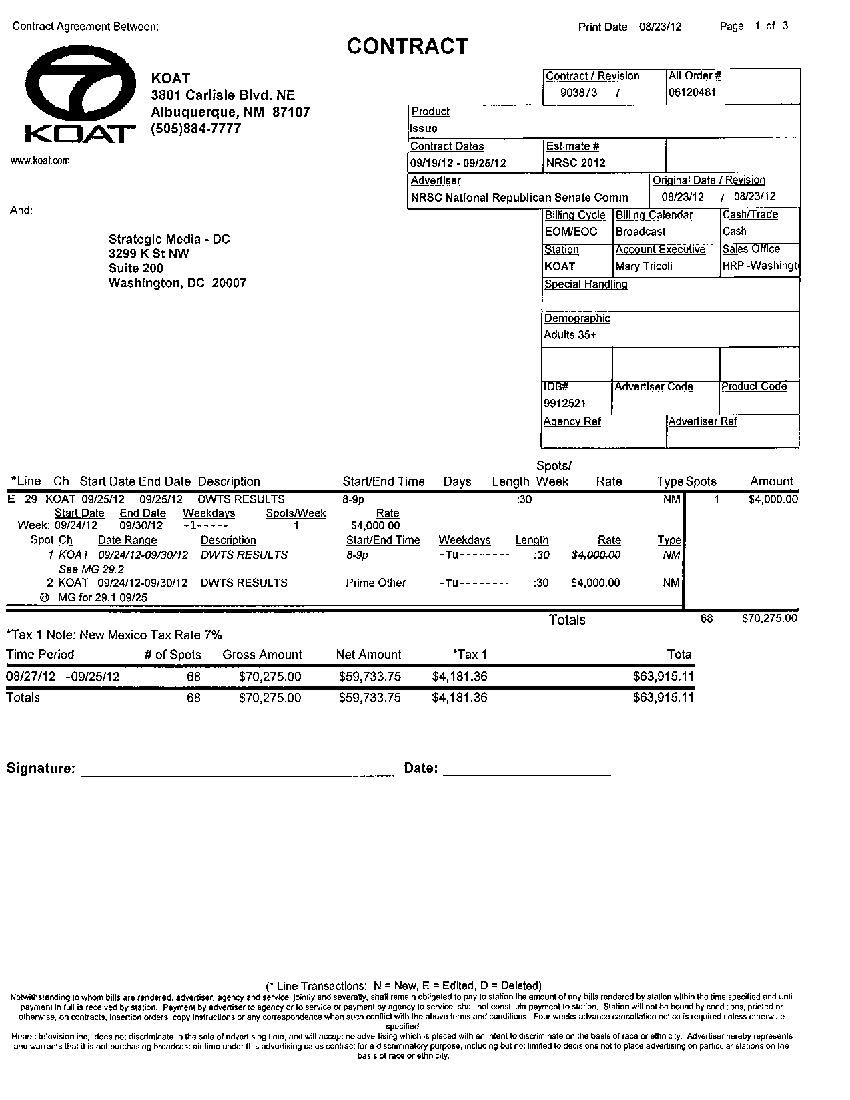

In [11]:
with pdfplumber.open(SCANNED) as pdf:
    page = pdf.pages[0]
    print(
        f"Scanned invoice, page 1 of {len(pdf.pages)}: {len(page.chars)} characters, {len(page.images)} image"
    )
    print(f"Text pdfplumber extracts: {page.extract_text()!r}")
    image = page.to_image(resolution=100).original

image

## 3. Data Ectraction using LLMs

First, let's define our schema `AdBuyInvoice` using Pydantics. It lists every field we want from an invoice, with its type and a short description. This schema will help the LLM extract the data based on the description and also validate the model outputs.

In [ ]:
from datetime import date

from pydantic import BaseModel, Field


class LineItem(BaseModel):
    channel: str | None = Field(
        None, description="The channel number the ads air on, e.g. 9"
    )
    program_desc: str | None = Field(
        None,
        description="Only the program or time slot from the Description column, e.g. M-F 5p-6p",
    )
    program_start_date: date | None = Field(
        None, description="The first day this line item airs"
    )
    program_end_date: date | None = Field(
        None, description="The last day this line item airs"
    )
    sub_amount: float | None = Field(
        None, description="The line item's total Amount, not the rate per spot"
    )


class AdBuyInvoice(BaseModel):
    advertiser: str | None = Field(
        None, description="The campaign or group buying the ads"
    )
    agency: str | None = Field(
        None, description="The ad agency placing the order, if any"
    )
    contract_num: str | None = Field(None, description="The contract or order number")
    property: str | None = Field(
        None, description="The TV station's call sign, e.g. KMSP"
    )
    product: str | None = Field(
        None, description="The product or campaign the ads are for"
    )
    tv_address: str | None = Field(None, description="The TV station's address")
    flight_from: date | None = Field(None, description="The first day the ads run")
    flight_to: date | None = Field(None, description="The last day the ads run")
    gross_amount: float | None = Field(
        None, description="The invoice total, before agency commission"
    )
    line_items: list[LineItem] = Field(default_factory=list)

In [13]:
from pydantic import ValidationError

try:
    AdBuyInvoice.model_validate({"gross_amount": "a lot", "flight_from": "next week"})
except ValidationError as error:
    print(error)

2 validation errors for AdBuyInvoice
flight_from
  Input should be a valid date or datetime, input is too short [type=date_from_datetime_parsing, input_value='next week', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/date_from_datetime_parsing
gross_amount
  Input should be a valid number, unable to parse string as a number [type=float_parsing, input_value='a lot', input_type=str]
    For further information visit https://errors.pydantic.dev/2.13/v/float_parsing


## 4. Ask the model to fill the schema

For each page, we send its text if it has a text layer, or its image if it's scanned. `responses.parse` validates the reply against `AdBuyInvoice`.

In [14]:
import base64
import io

from openai import OpenAI

MODEL = "gpt-5.2"
INSTRUCTIONS = (
    "Extract this TV station's ad-buy invoice into the schema. Copy names and numbers "
    "as the invoice shows them. Write dates as YYYY-MM-DD: a two-digit year like 20 "
    "means 2020. Leave a field empty if it isn't on the invoice."
)


def scanned_pages(path: Path) -> list[bool]:
    """For each page, whether it's scanned: pdfplumber finds (almost) no text on it."""
    with pdfplumber.open(path) as pdf:
        return [len(page.chars) < 20 for page in pdf.pages]


def page_text(path: Path, number: int) -> str:
    """The text of one page, from its text layer."""
    with pdfplumber.open(path) as pdf:
        return pdf.pages[number].extract_text() or ""


def page_image(path: Path, number: int) -> str:
    """One page as a PNG data URL, ready to send to a multimodal model."""
    with pdfplumber.open(path) as pdf:
        image = pdf.pages[number].to_image(resolution=150).original
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    return "data:image/png;base64," + base64.b64encode(buffer.getvalue()).decode()


def ask_model(content: list[dict]) -> tuple[AdBuyInvoice, int]:
    """Ask the model to fill the schema. Returns the invoice and the input tokens it used."""
    response = OpenAI().responses.parse(
        model=MODEL,
        input=[{"role": "user", "content": content}],
        text_format=AdBuyInvoice,
    )
    # parse() validates the reply against the schema, so this is an AdBuyInvoice or an error.
    return response.output_parsed, response.usage.input_tokens


In [15]:
def extract(path: Path) -> tuple[AdBuyInvoice, int]:
    """Send each page's text if it has a text layer, or its image if it's scanned."""
    content = [{"type": "input_text", "text": INSTRUCTIONS}]
    for number, scanned in enumerate(scanned_pages(path)):
        if scanned:
            content.append(
                {"type": "input_image", "image_url": page_image(path, number)}
            )
        else:
            content.append(
                {
                    "type": "input_text",
                    "text": f"Page {number + 1}:\n{page_text(path, number)}",
                }
            )
    return ask_model(content)

## 5. Compare each field with the ground truth

We use the VRDU benchmark's own match functions, which allow for small differences, such as date formats or extra spaces.

In [ ]:
from invoices import (
    FIELDS,
    field_correct,
    line_items_correct,
    load_ground_truth,
    matches,
)

truth = load_ground_truth()


def compare(path: Path, invoice: AdBuyInvoice) -> None:
    expected = truth[path.name]
    print(f"{'field':<14} {'extracted':<38} {'ground truth':<38} result")
    for field in FIELDS:
        correct = field_correct(field, invoice, expected)
        label = (expected["fields"].get(field) or ["-"])[0]
        result = "-" if correct is None else ("match" if correct else "MISMATCH")
        print(
            f"{field:<14} {str(getattr(invoice, field))[:37]:<38} {label[:37]:<38} {result}"
        )
    items = line_items_correct(invoice, expected)
    print(
        f"{'line_items':<14} {len(invoice.line_items):<38} {len(expected['line_items']):<38} "
        f"{'-' if items is None else ('match' if items else 'MISMATCH')}"
    )

    # Each annotated line item must be found with the same program and amount.
    print(f"\n{'line item':<14} {'extracted':<38} {'ground truth':<38} result")
    for n in range(max(len(invoice.line_items), len(expected["line_items"]))):
        got = invoice.line_items[n] if n < len(invoice.line_items) else None
        gold = expected["line_items"][n] if n < len(expected["line_items"]) else None
        extracted = f"{got.program_desc} | {got.sub_amount}" if got else "-"
        wanted = (
            f"{gold.get('program_desc')} | {gold.get('sub_amount')}" if gold else "-"
        )
        found = gold and any(
            all(
                matches(f, getattr(e, f), [gold[f]])
                for f in ("program_desc", "sub_amount")
                if f in gold
            )
            for e in invoice.line_items
        )
        result = "-" if gold is None else ("match" if found else "MISMATCH")
        print(f"{n + 1:<14} {extracted[:37]:<38} {wanted[:37]:<38} {result}")

In [17]:
digital, digital_tokens = extract(DIGITAL)
print(f"Input tokens: {digital_tokens}\n")
compare(DIGITAL, digital)

Input tokens: 1430

field          extracted                              ground truth                           result
advertiser     POL/Joe Biden/President/US/Dem         POL/Joe Biden/President/US/Dem         match
agency         Media Buying and Analytics             -                                      -
contract_num   2186808 / 26660858                     2186808                                MISMATCH
property       WYCW                                   WYCW                                   match
product        Primary                                Primary                                match
tv_address     2960 North Meridian Street Indianapol  2960 North Meridian Street Jill Hammo  MISMATCH
flight_from    2020-01-28                             01/28/20                               match
flight_to      2020-02-03                             02/03/20                               match
gross_amount   1345.0                                 $1,345.00                       

In [18]:
scanned, scanned_tokens = extract(SCANNED)
print(f"Input tokens: {scanned_tokens}\n")
compare(SCANNED, scanned)

Input tokens: 3093

field          extracted                              ground truth                           result
advertiser     NRSC National Republican Senate Comm   NRSC National Republican Senate Comm   match
agency         Strategic Media - DC                   -                                      -
contract_num   903873                                 903873                                 match
property       KOAT                                   KOAT                                   match
product                                               Issue                                  MISMATCH
tv_address     3801 Carlisle Blvd. NE
Albuquerque, N  3801 Carlisle Blvd. NE Albuquerque, N  match
flight_from    2012-09-19                             09/19/12                               match
flight_to      2012-09-25                             09/25/12                               match
gross_amount   70275.0                                $70,275.00                         

## 6. What if we just send the PDF?

The API also accepts a PDF file directly. The provider then extracts the text and page images itself, and we can't see what the model got. Let's compare the result and the cost with our pdfplumber version.

In [19]:
def extract_from_pdf(path: Path) -> tuple[AdBuyInvoice, int]:
    """Send the whole PDF file and let the provider read it."""
    data = base64.b64encode(path.read_bytes()).decode()
    content = [
        {"type": "input_text", "text": INSTRUCTIONS},
        {
            "type": "input_file",
            "filename": path.name,
            "file_data": f"data:application/pdf;base64,{data}",
        },
    ]
    return ask_model(content)

In [20]:
digital_pdf, digital_pdf_tokens = extract_from_pdf(DIGITAL)
print(f"Input tokens: {digital_pdf_tokens}, against {digital_tokens} with pdfplumber\n")
compare(DIGITAL, digital_pdf)

Input tokens: 2531, against 1430 with pdfplumber

field          extracted                              ground truth                           result
advertiser     POL/Joe Biden/President/US/Dem         POL/Joe Biden/President/US/Dem         match
agency         Media Buying and Analytics             -                                      -
contract_num   2186808                                2186808                                match
property       WYCW                                   WYCW                                   match
product        Primary                                Primary                                match
tv_address     2960 North Meridian Street
Indianapol  2960 North Meridian Street Jill Hammo  MISMATCH
flight_from    2020-01-28                             01/28/20                               match
flight_to      2020-02-03                             02/03/20                               match
gross_amount   1345.0                                 $1,34

In [21]:
scanned_pdf, scanned_pdf_tokens = extract_from_pdf(SCANNED)
print(f"Input tokens: {scanned_pdf_tokens}, against {scanned_tokens} with pdfplumber\n")
compare(SCANNED, scanned_pdf)

Input tokens: 1565, against 3093 with pdfplumber

field          extracted                              ground truth                           result
advertiser     NRSC National Republican Senate Comm   NRSC National Republican Senate Comm   match
agency         Strategic Media - DC                   -                                      -
contract_num   903873 /                               903873                                 match
property       KOAT                                   KOAT                                   match
product                                               Issue                                  MISMATCH
tv_address     3801 Carlisle Blvd. NE
Albuquerque, N  3801 Carlisle Blvd. NE Albuquerque, N  match
flight_from    2012-09-19                             09/19/12                               match
flight_to      2012-09-25                             09/25/12                               match
gross_amount   70275.0                                $70,2